# BANK CUSTOMER CHURN PREDICTION
##### Code By Siddhartha Mettu

### 1. IMPORT LIBRARIES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

### 2. LOAD DATASET

In [2]:
file_path =  r"C:\Users\Siddhartha Mettu\OneDrive\Desktop\Internship\Churn\Churn_Modelling.csv"
df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (10000, 14)
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826

### 3. EXPLORATORY DATA ANALYSIS

In [3]:
print("===== BASIC INFO =====")
print(df.info())

print("===== SUMMARY STATISTICS =====")
print(df.describe())

===== BASIC INFO =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB
None
===== SUMMARY STATISTICS =====
         RowNumber    CustomerId   

##### Target Distribution

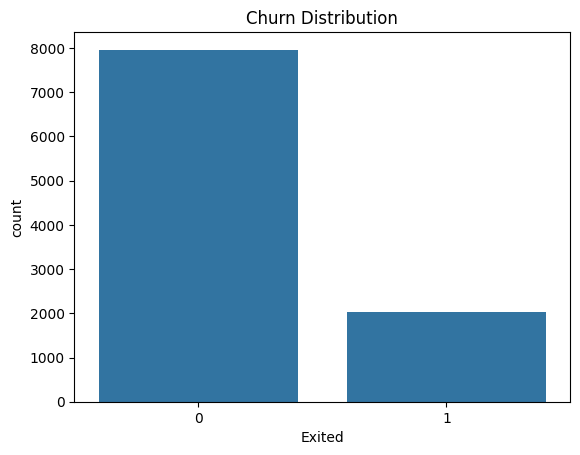

In [4]:
sns.countplot(x='Exited', data=df)
plt.title('Churn Distribution')
plt.show()

##### Gender Distribution

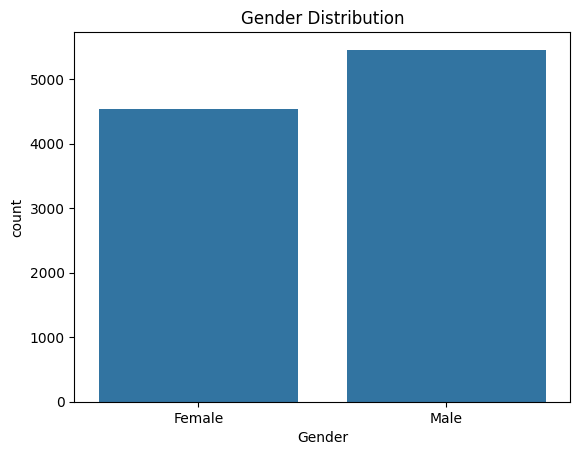

In [5]:
sns.countplot(x='Gender', data=df)
plt.title('Gender Distribution')
plt.show()

##### Geography Distribution

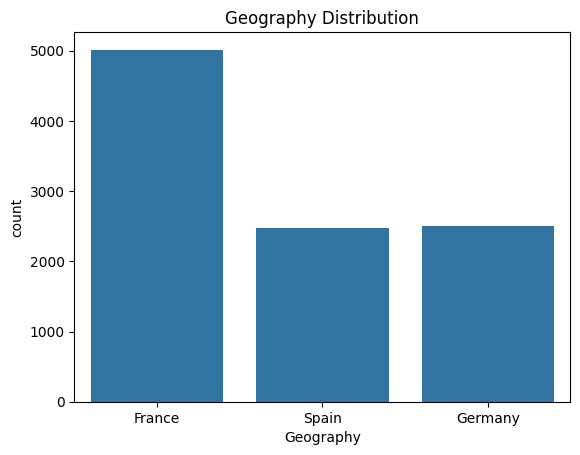

In [6]:
sns.countplot(x='Geography', data=df)
plt.title('Geography Distribution')
plt.show()

##### Age Distribution

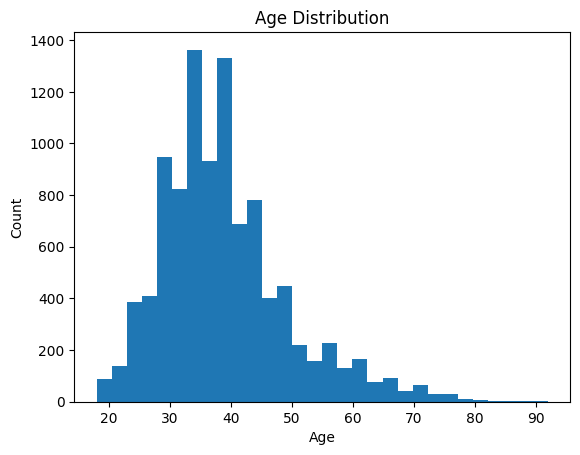

In [7]:
plt.hist(df['Age'], bins=30)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

##### Credit Score Distribution

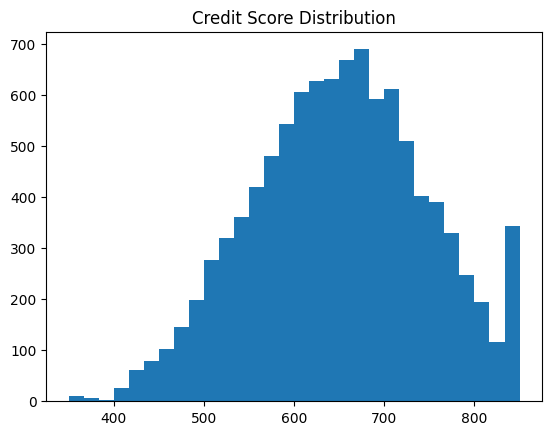

In [8]:
plt.hist(df['CreditScore'], bins=30)
plt.title('Credit Score Distribution')
plt.show()


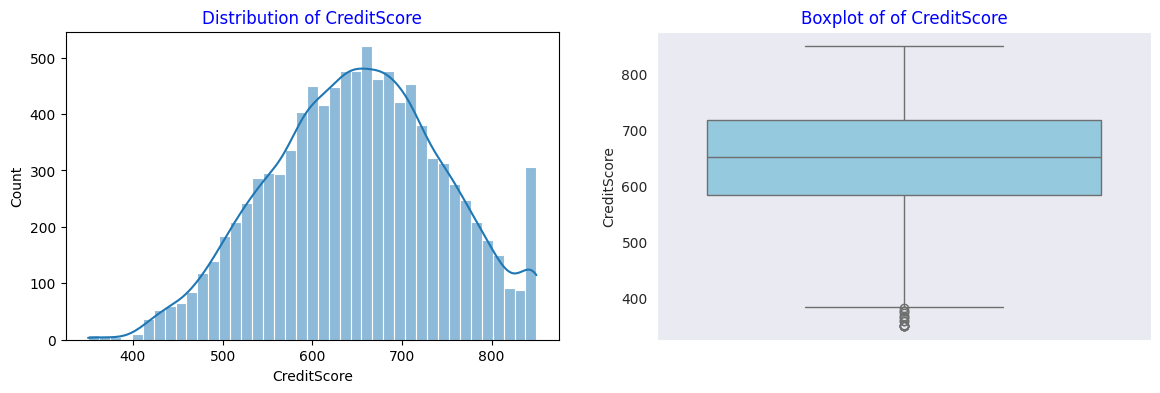

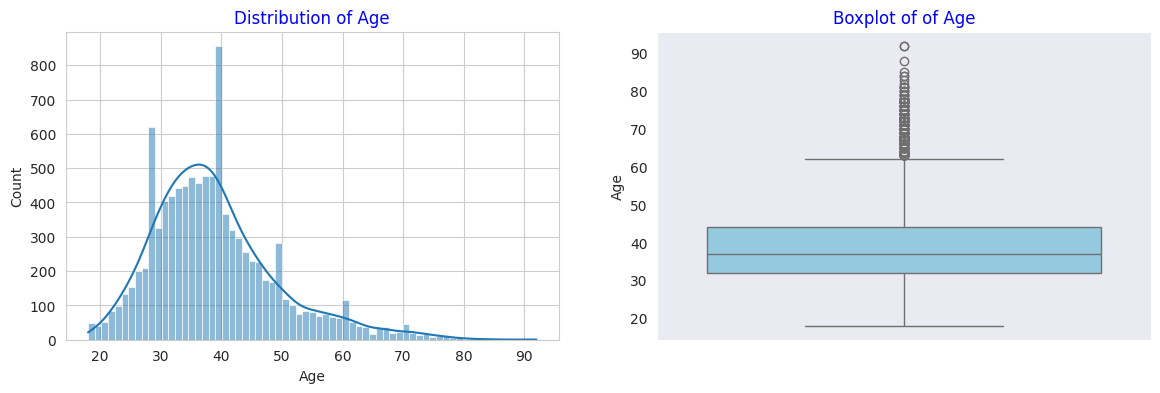

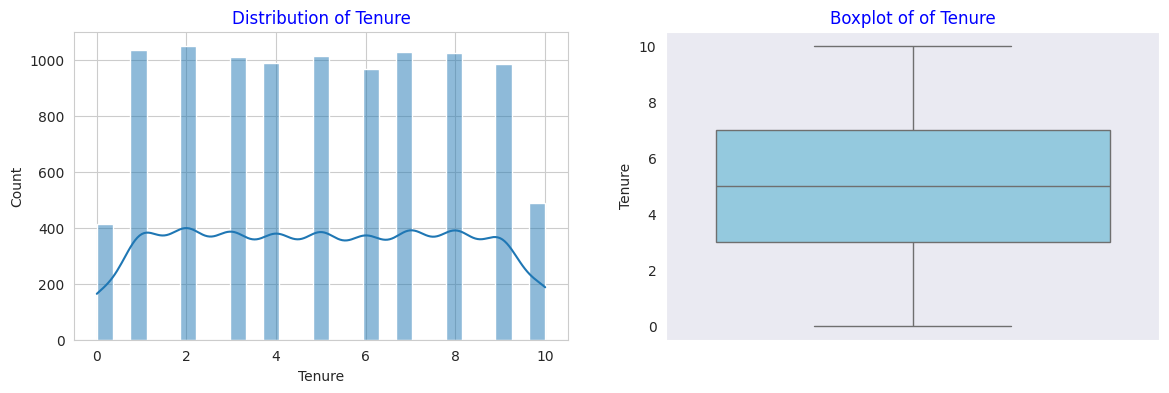

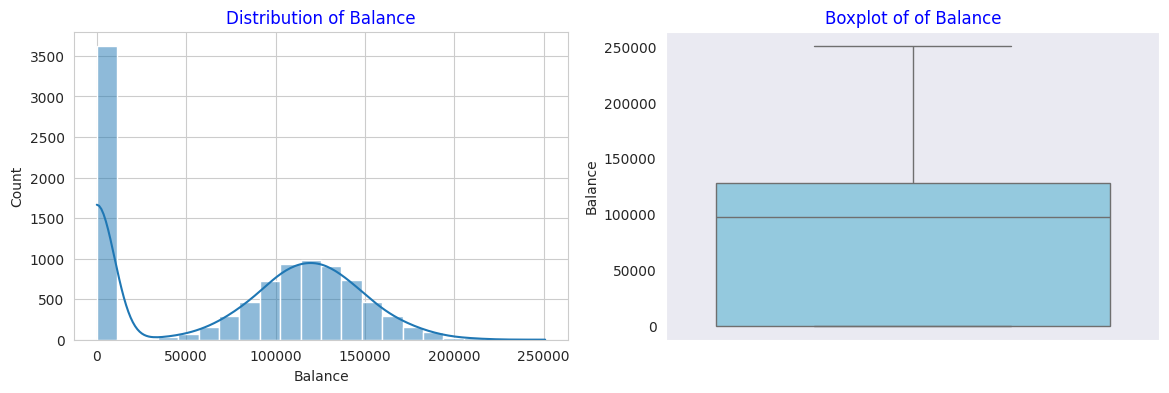

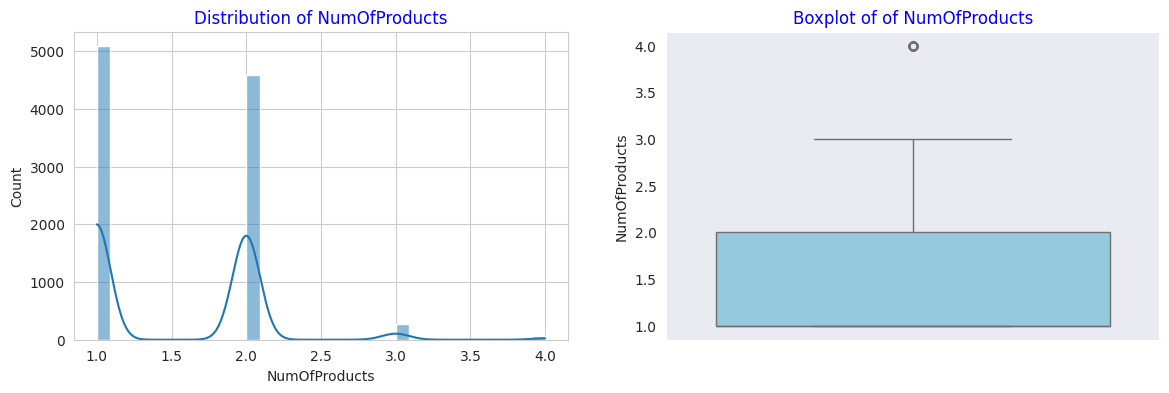

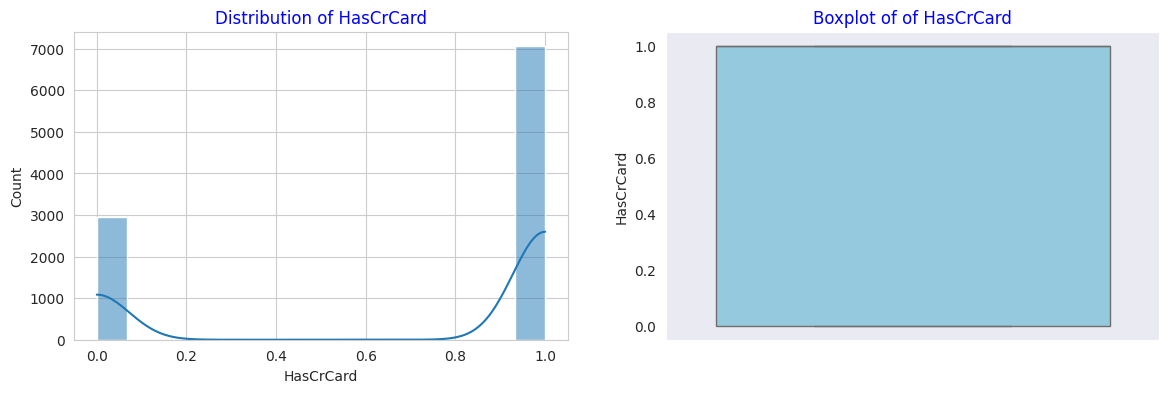

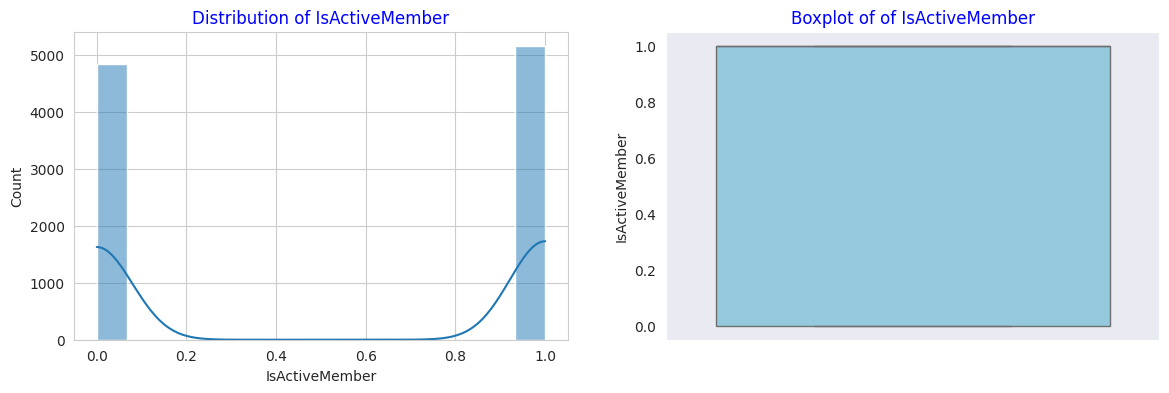

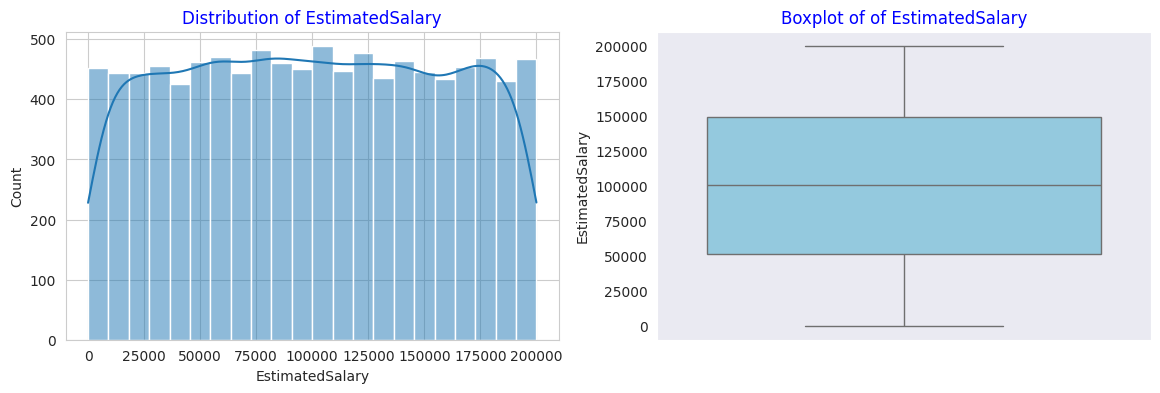

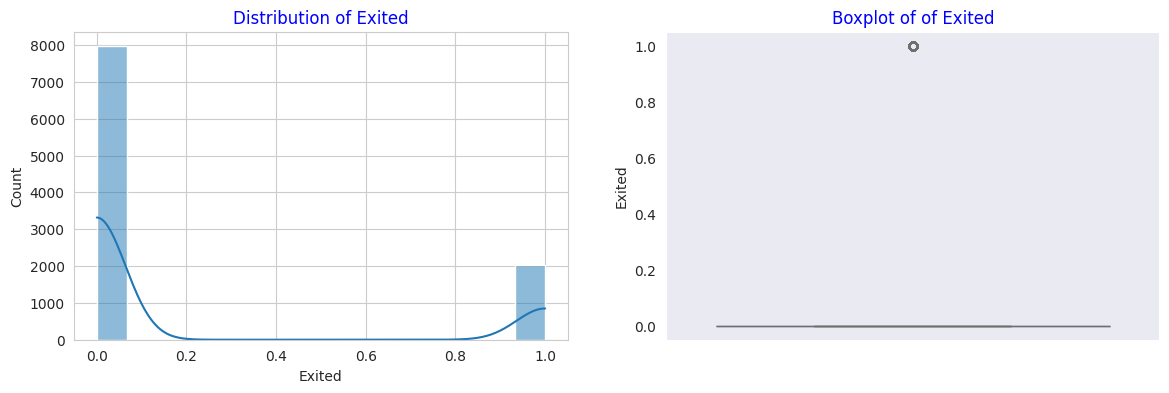

In [9]:
for i in (df.select_dtypes(exclude='object').columns[2:]):
    plt.figure(figsize=(14,4))

    plt.subplot(1, 2, 1)
    sns.set_style('dark')
    sns.histplot(df[i],kde=True)
    plt.title(f'Distribution of {i}',color='b')
    
    plt.subplot(1, 2, 2)
    sns.set_style('whitegrid')
    sns.boxplot(df[i],color='skyblue')
    plt.title(f'Boxplot of of {i}',color='b')
plt.show()

##### Balance Distribution

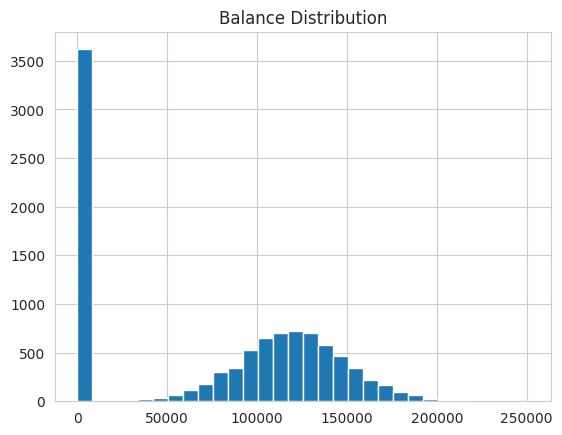

In [10]:
plt.hist(df['Balance'], bins=30)
plt.title('Balance Distribution')
plt.show()

##### Tenure vs Churn

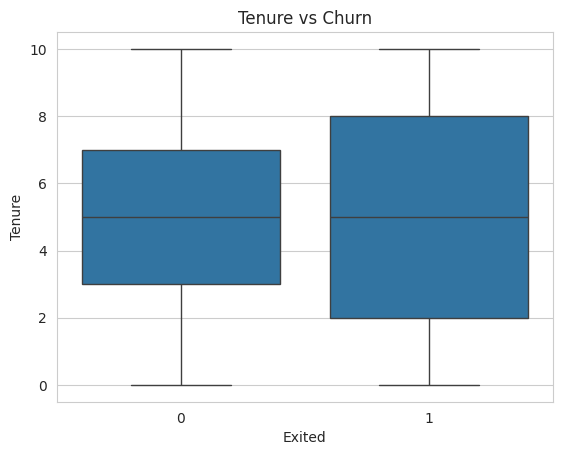

In [11]:
sns.boxplot(x='Exited', y='Tenure', data=df)
plt.title('Tenure vs Churn')
plt.show()

##### Age vs Churn

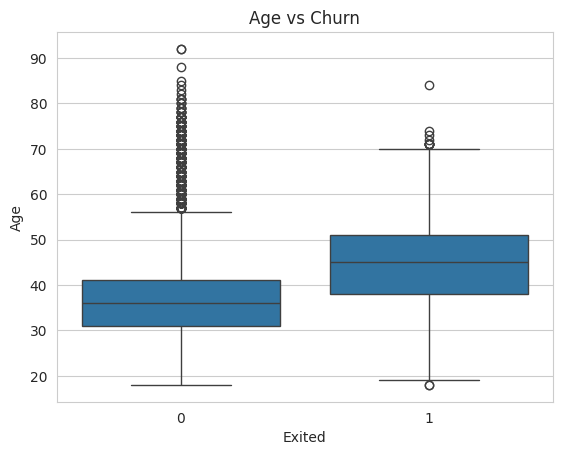

In [12]:
sns.boxplot(x='Exited', y='Age', data=df)
plt.title('Age vs Churn')
plt.show()

##### Balance vs Churn

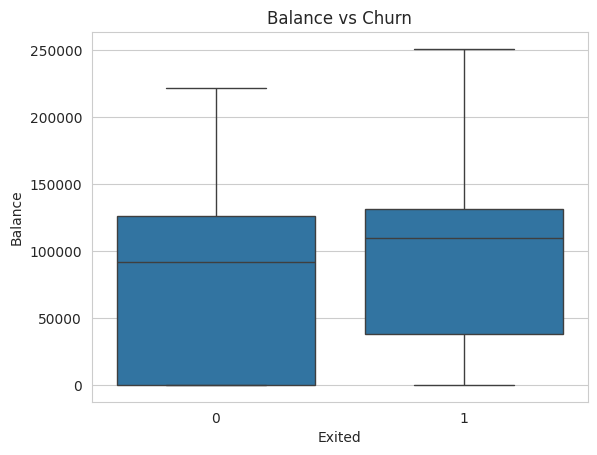

In [13]:
sns.boxplot(x='Exited', y='Balance', data=df)
plt.title('Balance vs Churn')
plt.show()

##### Correlation Heatmap

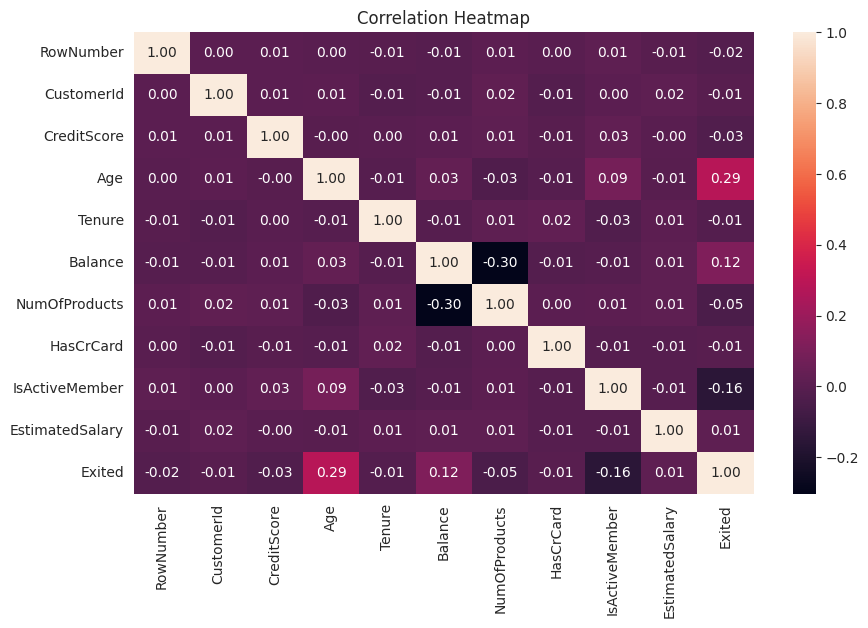

In [14]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

##### Analysis culomns By Exited


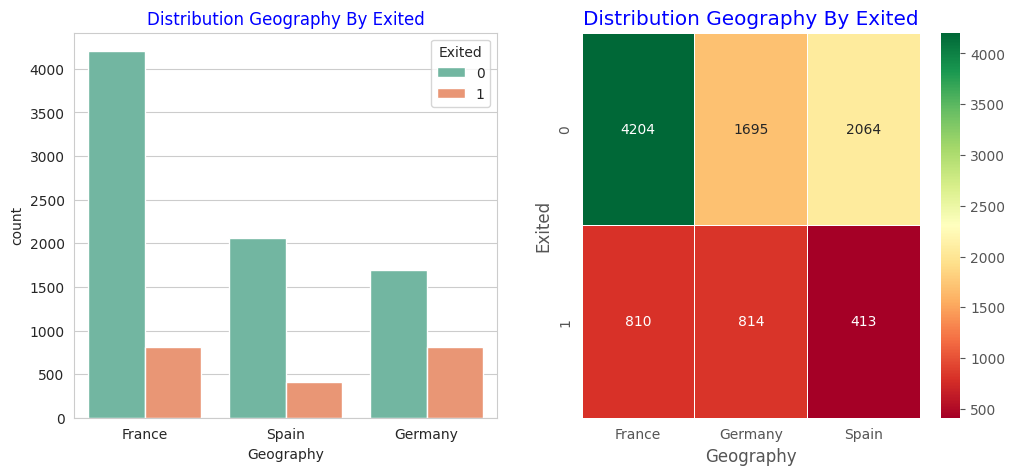

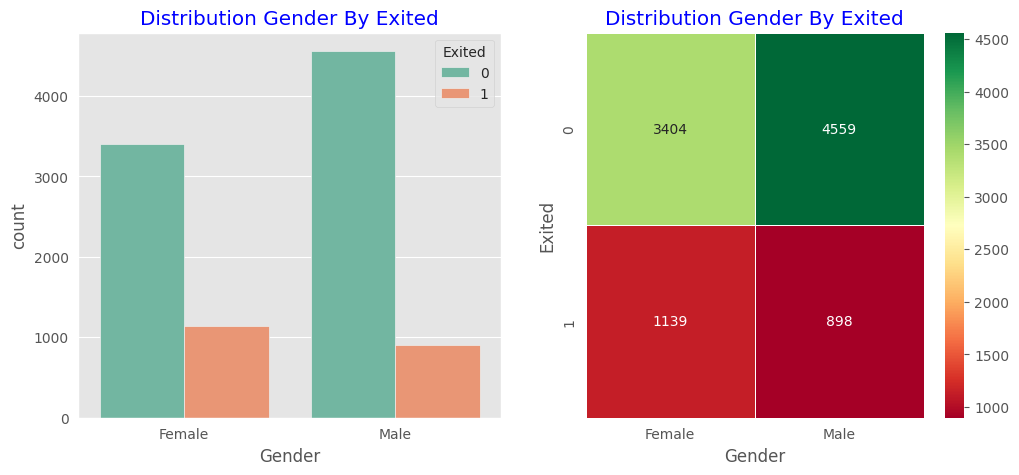

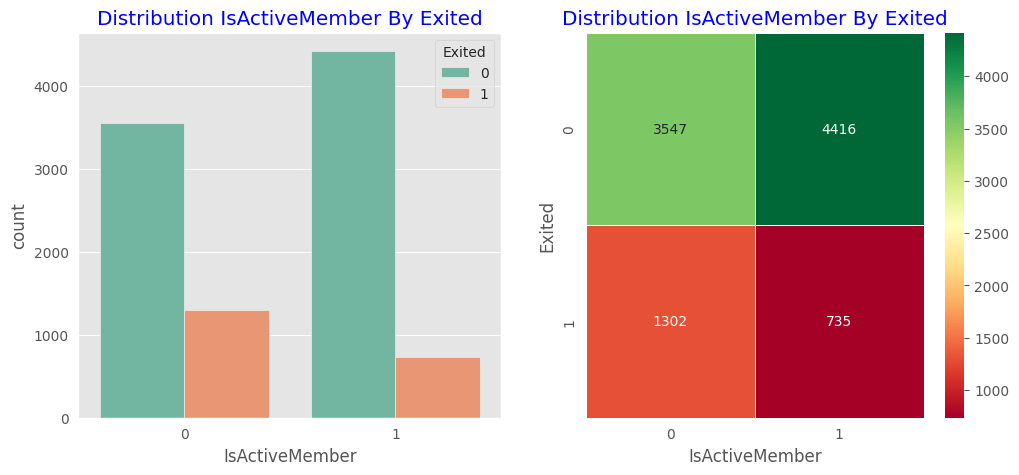

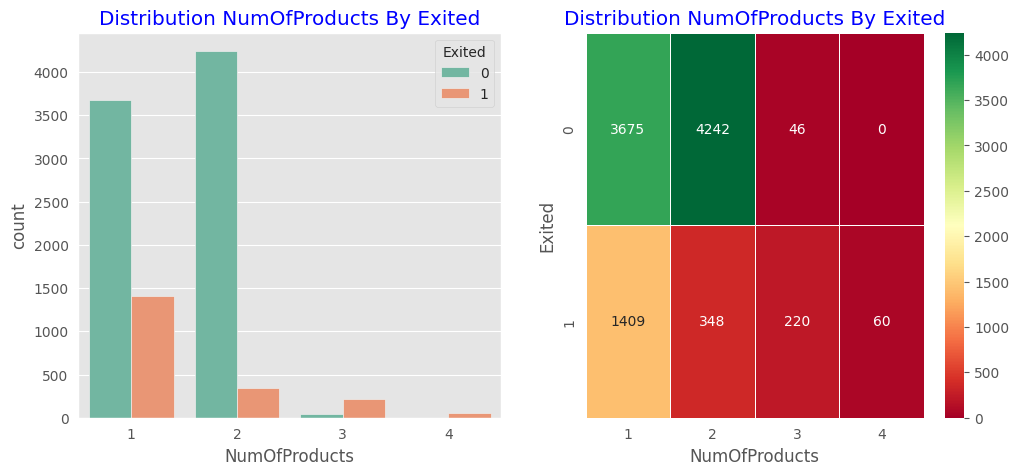

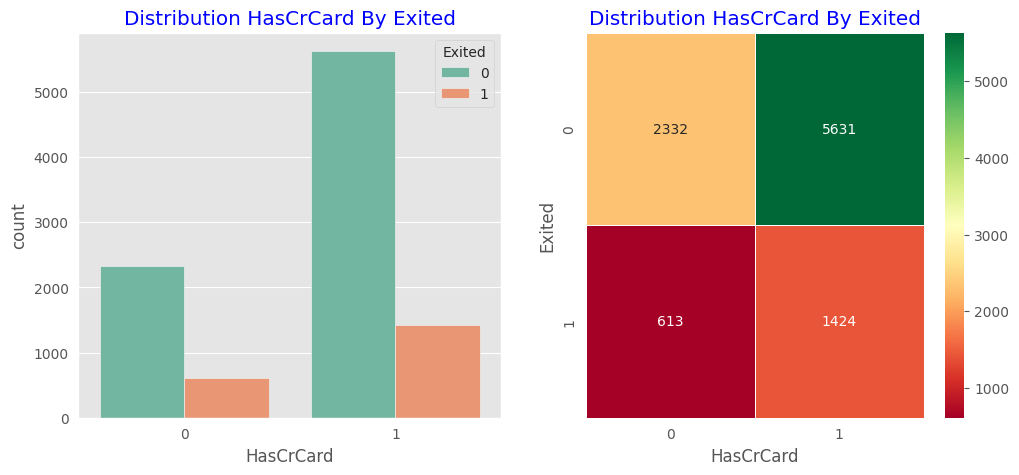

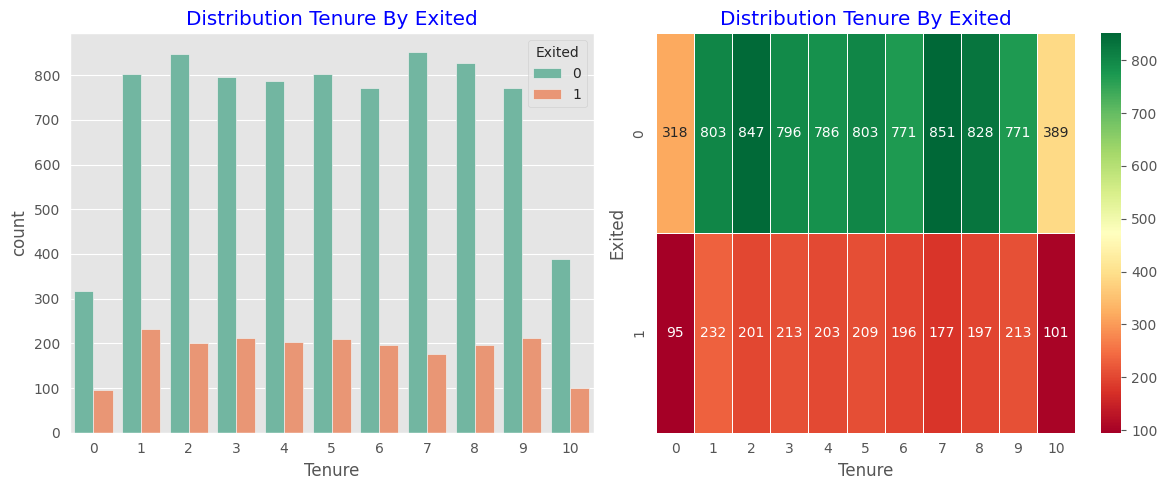

In [15]:
names=['Geography','Gender','IsActiveMember','NumOfProducts','HasCrCard','Tenure']
for i in names:
    plt.figure(figsize=(12,5))
    plt.subplot(1,2,1)
    sns.countplot(x=df[i],hue=df['Exited'],palette='Set2')
    plt.title(f'Distribution {i} By Exited',color='b')
    plt.style.use('ggplot')
    
    plt.subplot(1,2,2)
    plt.title(f'Distribution {i} By Exited',color='b')
    ct=pd.crosstab(df['Exited'],df[i])
    sns.heatmap(ct,annot=True,fmt='0.0f',linewidths=0.5,cmap='RdYlGn')
plt.tight_layout()
plt.show()

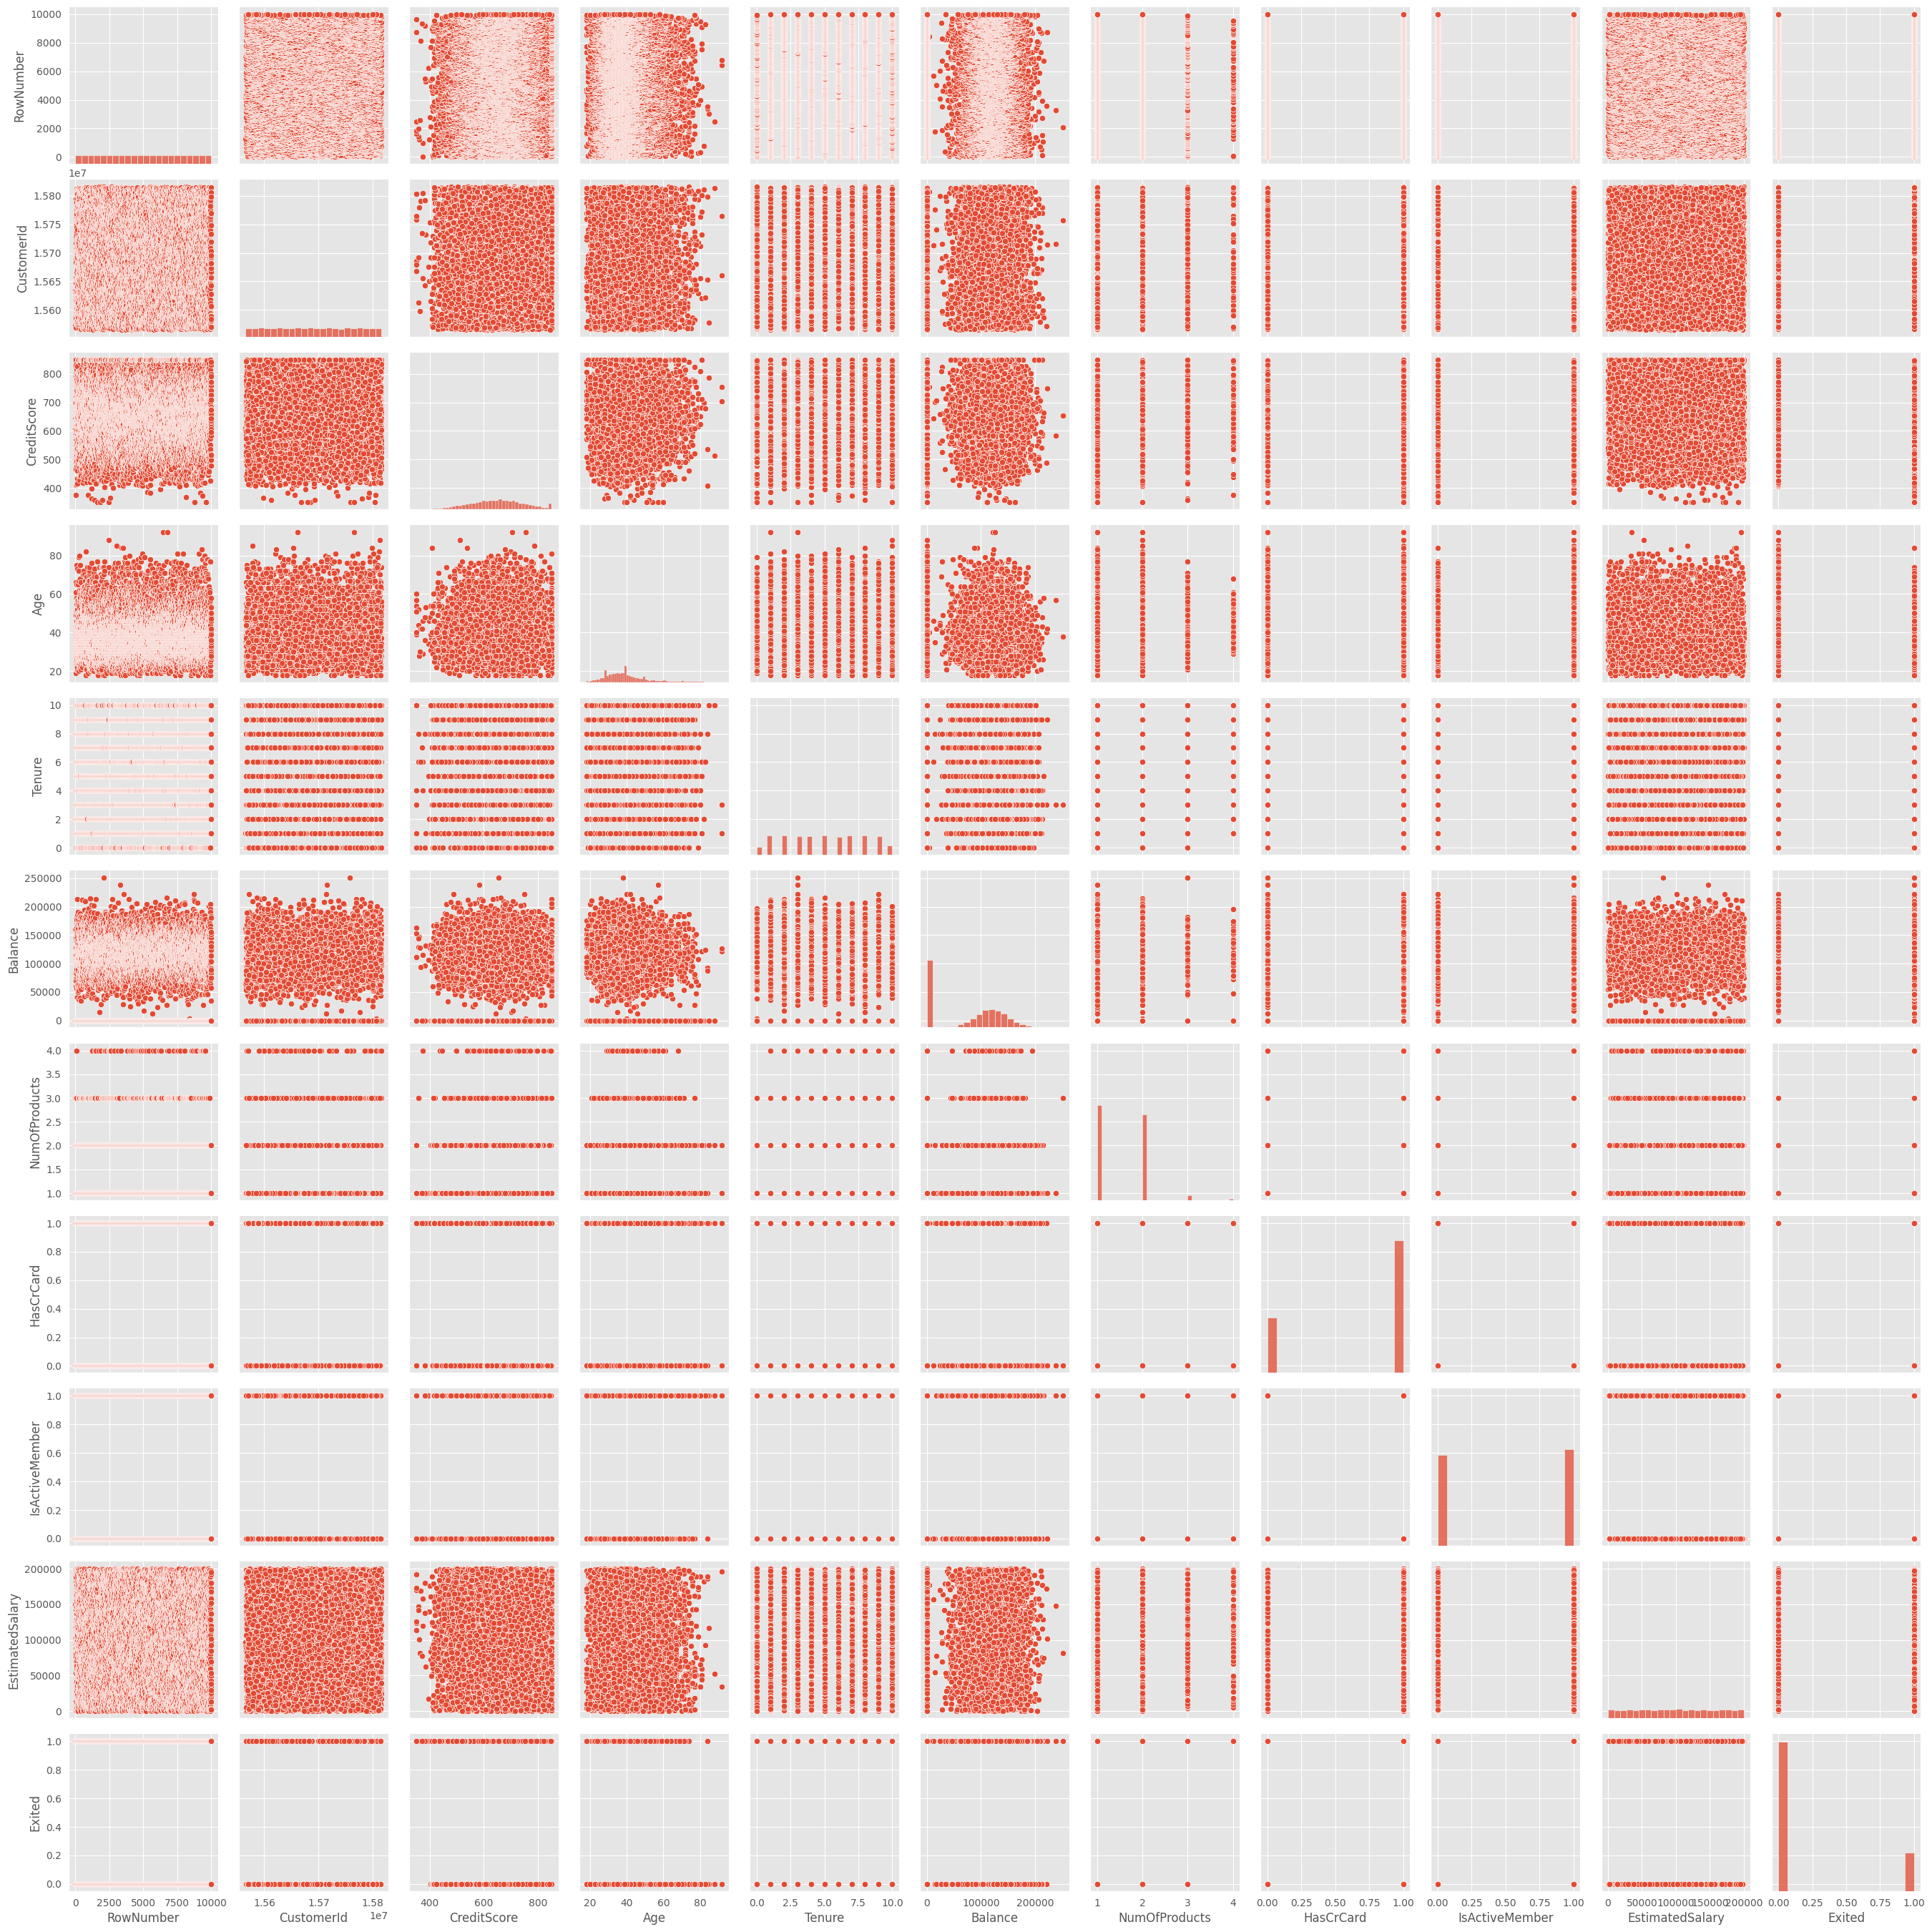

In [16]:
sns.pairplot(df)
plt.show()

### 4. DATA PREPROCESSING

In [17]:
# Drop irrelevant columns
X = df.drop(columns=['RowNumber', 'CustomerId', 'Surname', 'Exited'])
y = df['Exited']

# Identify categorical and numerical columns
categorical_cols = ['Geography', 'Gender']
numerical_cols = [col for col in X.columns if col not in categorical_cols]

# Preprocessing pipelines
numeric_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(drop='first')

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

### 5. TRAIN-TEST SPLIT

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)


Train size: (8000, 10)
Test size: (2000, 10)


### 6. Models

##### MODEL 1: LOGISTIC REGRESSION

In [19]:
log_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression())
])

log_model.fit(X_train, y_train)

y_pred_log = log_model.predict(X_test)

y_prob_log = log_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_log))
print("Classification Report:\n", classification_report(y_test, y_pred_log))


Accuracy: 0.808
ROC-AUC: 0.77475626628169
Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.97      0.89      1593
           1       0.59      0.19      0.28       407

    accuracy                           0.81      2000
   macro avg       0.71      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000



##### MODEL 2: RANDOM FOREST

In [20]:
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))
print("Classification Report:\n", classification_report(y_test, y_pred_rf))


Accuracy: 0.864
ROC-AUC: 0.8522181657774878
Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.97      0.92      1593
           1       0.78      0.46      0.58       407

    accuracy                           0.86      2000
   macro avg       0.83      0.71      0.75      2000
weighted avg       0.86      0.86      0.85      2000



##### MODEL 3: GRADIENT BOOSTING

In [21]:
gb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=42))
])

gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_gb))
print("Classification Report:\n", classification_report(y_test, y_pred_gb))


Accuracy: 0.87
ROC-AUC: 0.8708307691358538
Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.97      0.92      1593
           1       0.79      0.49      0.60       407

    accuracy                           0.87      2000
   macro avg       0.84      0.73      0.76      2000
weighted avg       0.86      0.87      0.86      2000



### 7. MODEL COMPARISON

In [22]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'Gradient Boosting'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_gb)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, y_prob_log),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_gb)
    ]
})

print("\n===== MODEL COMPARISON =====")
print(results)


===== MODEL COMPARISON =====
                 Model  Accuracy   ROC-AUC
0  Logistic Regression     0.808  0.774756
1        Random Forest     0.864  0.852218
2    Gradient Boosting     0.870  0.870831


### 8. CONFUSION MATRICES

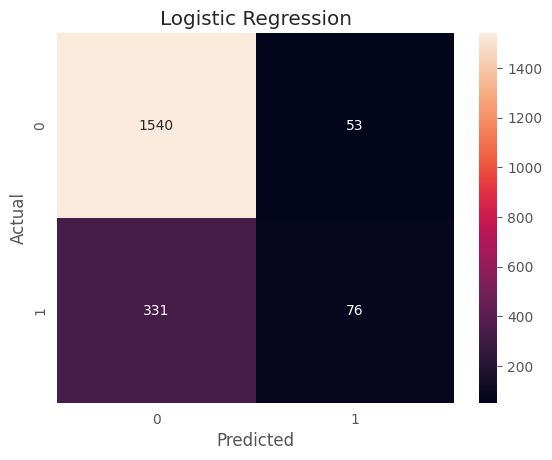

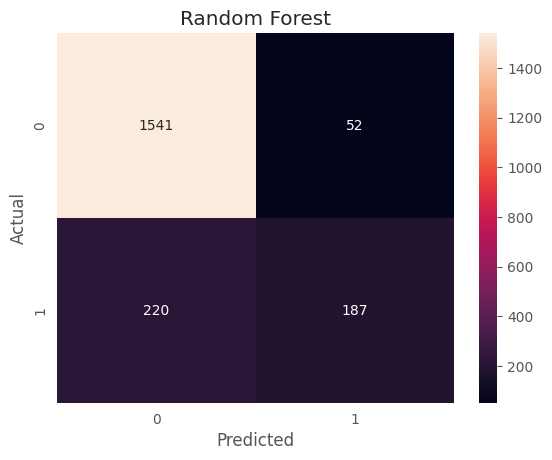

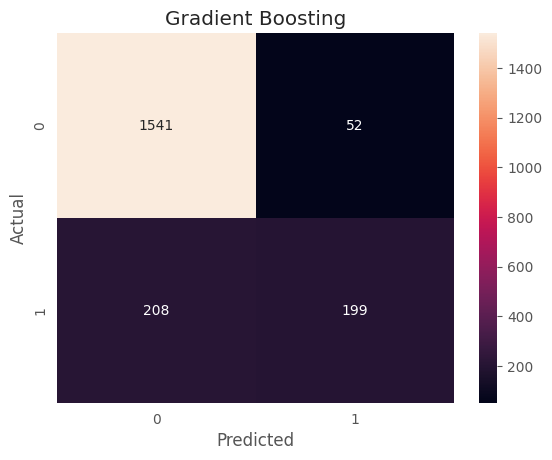

In [23]:
def plot_conf_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d')
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

plot_conf_matrix(y_test, y_pred_log, "Logistic Regression")
plot_conf_matrix(y_test, y_pred_rf, "Random Forest")
plot_conf_matrix(y_test, y_pred_gb, "Gradient Boosting")

### SAMPLE PREDICTION

In [24]:
sample = X_test.iloc[[67]]
print("Sample Input:\n", sample)

print("Logistic Prediction:", log_model.predict(sample))
print("Random Forest Prediction:", rf_model.predict(sample))
print("Gradient Boosting Prediction:", gb_model.predict(sample))

Sample Input:
      CreditScore Geography Gender  Age  Tenure  Balance  NumOfProducts  \
593          630     Spain   Male   32       4  82034.0              1   

     HasCrCard  IsActiveMember  EstimatedSalary  
593          0               0        146326.45  
Logistic Prediction: [0]
Random Forest Prediction: [0]
Gradient Boosting Prediction: [0]


## ARTIFICIAL NEURAL NETWORK (ANN)

In [25]:

pip install tensorflow==2.10

ERROR: Could not find a version that satisfies the requirement tensorflow==2.10 (from versions: 2.16.0rc0, 2.16.1, 2.16.2, 2.17.0rc0, 2.17.0rc1, 2.17.0, 2.17.1, 2.18.0rc0, 2.18.0rc1, 2.18.0rc2, 2.18.0, 2.18.1, 2.19.0rc0, 2.19.0, 2.19.1, 2.20.0rc0, 2.20.0, 2.21.0rc0, 2.21.0rc1, 2.21.0)
ERROR: No matching distribution found for tensorflow==2.10
Note: you may need to restart the kernel to use updated packages.


In [26]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Prepare processed data separately for ANN
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

input_dim = X_train_prep.shape[1]

ann_model = Sequential([
    Dense(64, activation='relu', input_dim=input_dim),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

ann_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = ann_model.fit(
    X_train_prep, y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=256,
    callbacks=[early_stop],
    verbose=1
)

2026-03-31 14:58:20.517712: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1774969100.721992      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1774969100.778451      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1774969101.240164      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774969101.240204      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774969101.240206      55 computation_placer.cc:177] computation placer alr

Epoch 1/30


I0000 00:00:1774969125.177060     134 service.cc:152] XLA service 0x7aa06400a970 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1774969125.177095     134 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1774969125.177101     134 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1774969125.498114     134 cuda_dnn.cc:529] Loaded cuDNN version 91002


23/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5342 - loss: 0.6974 

I0000 00:00:1774969127.191494     134 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.5498 - loss: 0.6892 - val_accuracy: 0.8000 - val_loss: 0.5141
Epoch 2/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7954 - loss: 0.5245 - val_accuracy: 0.8000 - val_loss: 0.4702
Epoch 3/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7971 - loss: 0.4833 - val_accuracy: 0.8019 - val_loss: 0.4464
Epoch 4/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7986 - loss: 0.4651 - val_accuracy: 0.8213 - val_loss: 0.4306
Epoch 5/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8125 - loss: 0.4432 - val_accuracy: 0.8338 - val_loss: 0.4222
Epoch 6/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8149 - loss: 0.4400 - val_accuracy: 0.8350 - val_loss: 0.4148
Epoch 7/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8213 - loss: 0.4302 - val_accuracy: 0.8394 - val_loss: 0.4069
Epoch 8/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8207 - loss: 0.4277 - val_accuracy: 0.8444 - val_loss: 0.4001
Ep

In [28]:
# Predictions
y_pred_ann_prob = ann_model.predict(X_test_prep).ravel()
y_pred_ann = (y_pred_ann_prob >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred_ann))
print("ROC-AUC:", roc_auc_score(y_test, y_pred_ann_prob))
print("Classification Report:", classification_report(y_test, y_pred_ann))

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
Accuracy: 0.8545
ROC-AUC: 0.852817378241107
Classification Report:               precision    recall  f1-score   support

           0       0.87      0.97      0.91      1593
           1       0.76      0.42      0.54       407

    accuracy                           0.85      2000
   macro avg       0.81      0.69      0.73      2000
weighted avg       0.84      0.85      0.84      2000



#### FINAL MODEL COMPARISON (INCLUDING ANN)

In [30]:
final_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'Gradient Boosting', 'ANN'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_gb),
        accuracy_score(y_test, y_pred_ann)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, y_prob_log),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_gb),
        roc_auc_score(y_test, y_pred_ann_prob)
    ]
})

print("===== FINAL MODEL COMPARISON =====")
print(final_results)

===== FINAL MODEL COMPARISON =====
                 Model  Accuracy   ROC-AUC
0  Logistic Regression    0.8080  0.774756
1        Random Forest    0.8640  0.852218
2    Gradient Boosting    0.8700  0.870831
3                  ANN    0.8545  0.852817
